In [ ]:
! pip install numpy >> /dev/null
! pip install pandas >> /dev/null
! pip install opencv-python >> /dev/null
! pip install matplotlib >> /dev/null
! pip install pycolmap >> /dev/null
! pip install gdown >> /dev/null

In [ ]:
! [ -d ../data/llff ] || (cd ../data && gdown 11PhkBXZZNYTD2emdG1awALlhCnkq7aN- -O llff.zip && unzip -q llff.zip && mv nerf_llff_data llff && rm llff.zip)
# ! [ -d ../data/dtu ] || (cd .. && python scripts/get_dtu.py get 8 21 30 34)

In [ ]:
import numpy as np
import pandas as pd
import cv2
import pycolmap
import matplotlib.pyplot as plt

from pathlib import Path

LLFF = Path("../data/llff")
DTU = Path("../data/dtu")
SCENES = ["fern", "flower", "fortress", "horns", "leaves", "orchids", "room", "trex"]
HOLD = 8
N_VIEWS = 3

### Dataset EDA

In [ ]:
def load(scene, root=LLFF):
    return pycolmap.Reconstruction(str(root / scene / "sparse" / "0"))
def views(rec):
    return sorted(rec.images.values(), key=lambda im: im.name)
def centres(rec):
    return np.array([im.projection_center() for im in views(rec)])
def split(n, k, hold=HOLD):
    ids = np.arange(n)
    test = ids[::hold]
    rest = np.setdiff1d(ids, test)
    train = rest[np.linspace(0, len(rest) - 1, k).astype(int)]
    return train, test
def angles(rec):
    v = views(rec)
    c = centres(rec)
    centroid = np.median(np.array([p.xyz for p in rec.points3D.values()]), axis=0)
    u = c - centroid
    u /= np.linalg.norm(u, axis=1, keepdims=True)
    about = np.degrees(np.arccos(np.clip(u @ u.T, -1, 1)))
    d = np.array([im.cam_from_world().rotation.matrix()[2] for im in v])
    d /= np.linalg.norm(d, axis=1, keepdims=True)
    optical = np.degrees(np.arccos(np.clip(d @ d.T, -1, 1)))
    return about, optical

tr, te = split(20, 3)
print("fern:", tr, te)  # [1 10 19] [0 8 16]

fern: [ 1 10 19] [ 0  8 16]


### 1

Each scene has 20-62 photos with res 4032 x 3024 from the same camera. Colmap matches features between the photos and works out the 3d points:

- `points` - how many 3d points colmap found
- `track_len` - how many photos see an average 3d point, example: fern has 4.09, so a point usually shows up in 4 of the 20 photos
- `seen_frac` - ^ that but a fraction 4/20
- `reproj_px` - take each 3d point, project it back into the photos that saw it, measure how far it lands from the 2d feature it came from

for few shot 3dgs we train on 3 photos. a 3d point can only be worked out from 2 or more photos that see it. if a typical point is in only 4 of 20 photos, the odds it lands in 2 of our 3 chosen photos are not good

In [ ]:
rows = []
for s in SCENES:
    r = load(s)
    cam = views(r)[0].camera
    rows.append({
        "scene": s,
        "views": r.num_images(),
        "points": r.num_points3D(),
        "track_len": r.compute_mean_track_length(),
        "reproj_px": r.compute_mean_reprojection_error(),
        "w": cam.width,
        "h": cam.height,
        "model": str(cam.model).split(".")[-1],
    })

inv = pd.DataFrame(rows).set_index("scene")
inv["seen_frac"] = inv.track_len / inv.views
inv.round(3)

,views,points,track_len,reproj_px,w,h,model,seen_frac
scene,,,,,,,,
fern,20,10091,4.092,1.153,4032,3024,SIMPLE_RADIAL,0.205
flower,34,23477,6.326,1.397,4032,3024,SIMPLE_RADIAL,0.186
fortress,42,41575,6.926,1.356,4032,3024,SIMPLE_RADIAL,0.165
horns,62,37399,10.485,1.229,4032,3024,SIMPLE_RADIAL,0.169
leaves,26,3294,8.163,1.523,4032,3024,SIMPLE_RADIAL,0.314
orchids,25,13105,4.457,1.222,4032,3024,SIMPLE_RADIAL,0.178
room,41,8772,7.093,1.079,4032,3024,SIMPLE_RADIAL,0.173
trex,55,33567,8.688,1.232,4032,3024,SIMPLE_RADIAL,0.158


`reproj_px` is colmap's number, computed with lens distortion modelled. ours will come out higher because we drop the SIMPLE_RADIAL distortion term the 3dgs loader every baseline uses drops it too, and matching them matters more than the fraction of a pixel it costs

### consecutive photos

the usual split one takes every 8th photo, which leaves each test photo sandwiched between two training photos. We also want a hard test: hold out a whole region the training photos never look at

Plot: each dot is the spot a photo was taken from, projected onto 2d. Colour is filename order, dark first. The grey
line joins the photos in that order.

- `span_deg` - stand where the subject is and watch the photographer. how many
  degrees do they travel across your view, between the two most separated
  photos? fern: 20 degrees.
- `step_deg` - the same between two consecutive photos
- `next_is_nearest` - for each photo find the physically closest other photo.
  how often is that the next or previous filename?

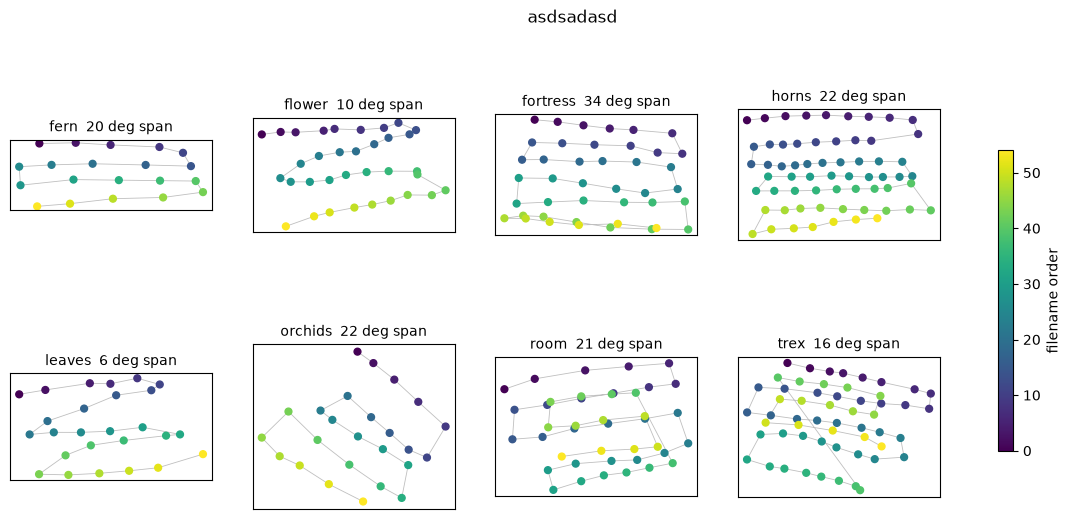

,photos,span_deg,step_deg,next_is_nearest
scene,,,,
fern,20,19.98,4.30,0.30
flower,34,10.20,1.03,0.97
fortress,42,34.07,5.09,0.19
horns,62,21.57,2.12,0.60
leaves,26,6.33,0.98,0.46
orchids,25,21.71,3.64,0.52
room,41,20.62,3.26,0.12
trex,55,15.95,1.88,0.35


In [5]:
def pca2(c):
    c = c - c.mean(0)
    _, _, vt = np.linalg.svd(c, full_matrices=False)
    return c @ vt[:2].T
def next_is_nearest(c):
    d = np.linalg.norm(c[:, None] - c[None, :], axis=2)
    np.fill_diagonal(d, np.inf)
    return (np.abs(d.argmin(1) - np.arange(len(c))) == 1).mean()


rows = []
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, s in zip(axes.ravel(), SCENES):
    r = load(s)
    c = centres(r)
    about, _ = angles(r)
    p = pca2(c)

    ax.plot(p[:, 0], p[:, 1], "-", lw=0.6, c="0.75", zorder=1)
    sc = ax.scatter(p[:, 0], p[:, 1], c=np.arange(len(p)), cmap="viridis", s=24, zorder=2)
    ax.set_title(f"{s}  {about.max():.0f} deg span", fontsize=10)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])

    rows.append({
        "scene": s,
        "photos": len(c),
        "span_deg": about.max(),
        "step_deg": np.median(np.diag(about, 1)),
        "next_is_nearest": next_is_nearest(c),
    })

fig.colorbar(sc, ax=axes, label="filename order", shrink=0.65)
fig.suptitle("asdsadasd")
plt.show()

shape = pd.DataFrame(rows).set_index("scene")
shape.round(2)

1. The captures are narrow: `span_deg` is 6 to 34 degrees. So every llff scene is someone stepping sideways a little while pointing a camera at one thing. That means "a region the training photos never look at" can only ever be a small step to the side on this dataset. It is a much weaker version of extrapolation than holding out the far side of an object

2. Filenames do not reliably follow positions. `next_is_nearest` ranges from 0.97 on flower down to 0.12 on room.

So holding out photos, for examplle, 20 to 25, would be a spatial region on flower and a random scatter on room


### standart split test

For each test photo, find the training photo closest to it in angle, and keep that angle. small: some training photo looks at nearly the same thing from nearly the same place, so reproducing the test photo barely requires knowing any 3d structure

- `about_mean` - the angle between two camera positions
- `about_max` - the worst single test photo in that scene
- `optical_mean` - the angle between the two cameras pointing directions. On forward-facing captures you can step sideways without turning the camera, so this can stay small while `about` grows

In [6]:
rows = []
for s in SCENES:
    r = load(s)
    about, optical = angles(r)
    tr, te = split(r.num_images(), N_VIEWS)
    rows.append({
        "scene": s,
        "about_mean": about[np.ix_(te, tr)].min(1).mean(),
        "about_max": about[np.ix_(te, tr)].min(1).max(),
        "optical_mean": optical[np.ix_(te, tr)].min(1).mean(),
    })

pd.DataFrame(rows).set_index("scene").round(2)

,about_mean,about_max,optical_mean
scene,,,
fern,6.16,11.07,4.72
flower,3.42,7.24,1.90
fortress,7.77,15.39,1.66
horns,4.95,11.27,5.83
leaves,1.12,1.53,1.99
orchids,3.97,6.03,5.68
room,4.68,9.10,3.39
trex,4.08,7.17,4.52


every test photo sits 1-8 degrees from its nearest training photo on average with 15 at worst 1-5 degrees between neighbouring photos: a test photo is usually about one photo-step away from a training one,so 8 split is easy

leaves is the extreme, 1.12 mean - its test photos are nearly duplicates of training photos. fortress is the hardest at 7.77 mean / 15.4 worst

the two definitions disagree a lot, fortress is 7.77 `about` vs 1.66 `optical`. the camera slides sideways without turning, so pointing direction barely changes while the viewpoint does. `about` is the one that tracks how much unseen geometry a test view actually asks for, so that is what sector_split should be pushing up

so these numbers are the bar - sector_split has to land clearly above them, otherwise it is not a harder test and the protocol axis shows nothing

### 4. Point survival

Colmap ran on all 20 photos, so the 3d points the model starts from were built using the 17 photos it is not supposed to have seen

How much of the starting point cloud actually depends on those hidden photos? A
3d point needs at least 2 photos, so of all points, how many are seen by at least 2 of the 3 training photos

- `all_views` - points colmap found using every photo
- `survive_3v` - of those, how many are still computable from the 3 training photos alone
- `frac_3v` - the second divided by the first

In [7]:
rows = []
for s in SCENES:
    r = load(s)
    v = views(r)
    ids = [im.image_id for im in v]
    row = {"scene": s, "all_views": r.num_points3D()}
    for k in (3, 9):
        tr, _ = split(len(v), k)
        keep = {ids[i] for i in tr}
        n = sum(1 for p in r.points3D.values()
                if sum(1 for e in p.track.elements if e.image_id in keep) >= 2)
        row[f"survive_{k}v"] = n
        row[f"frac_{k}v"] = n / r.num_points3D()
    rows.append(row)

surv = pd.DataFrame(rows).set_index("scene")
print(f"mean surviving fraction: {surv.frac_3v.mean():.1%} at 3 views, {surv.frac_9v.mean():.1%} at 9")
surv.round(4)

mean surviving fraction: 12.8% at 3 views, 40.9% at 9


,all_views,survive_3v,frac_3v,survive_9v,frac_9v
scene,,,,,
fern,10091,1418,0.1405,5077,0.5031
flower,23477,2416,0.1029,9034,0.3848
fortress,41575,4302,0.1035,14246,0.3427
horns,37399,3036,0.0812,13047,0.3489
leaves,3294,913,0.2772,2188,0.6642
orchids,13105,1210,0.0923,5090,0.3884
room,8772,1070,0.1220,3006,0.3427
trex,33567,3423,0.1020,9941,0.2962


this is just a count of points and not a trained model yet, but we can say that under the standart llff 3-view protocol only around 13% of initial 3d points are computable from the training views alone.

### resolution comparioson

llff ships every photo at three sizes: `images/`, `images_4/`, `images_8/` 
The published numbers are all at `images_8`, so that is what we use

In [9]:
rows = []
for s in SCENES:
    r = load(s)
    cam = views(r)[0].camera
    row = {"scene": s, "photos": r.num_images(), "colmap": f"{cam.width}x{cam.height}"}
    for d in (4, 8):
        files = sorted((LLFF / s / f"images_{d}").glob("*.png"))
        row[f"n_{d}"] = len(files)
        if files:
            h, w = cv2.imread(str(files[0])).shape[:2]
            row[f"images_{d}"] = f"{w}x{h}"
            row[f"ratio_{d}"] = cam.width / w
    rows.append(row)

res = pd.DataFrame(rows).set_index("scene")
res

,photos,colmap,n_4,images_4,ratio_4,n_8,images_8,ratio_8
scene,,,,,,,,
fern,20,4032x3024,20,1008x756,4.0,20,504x378,8.0
flower,34,4032x3024,34,1008x756,4.0,34,504x378,8.0
fortress,42,4032x3024,42,1008x756,4.0,42,504x378,8.0
horns,62,4032x3024,62,1008x756,4.0,62,504x378,8.0
leaves,26,4032x3024,26,1008x756,4.0,26,504x378,8.0
orchids,25,4032x3024,25,1008x756,4.0,25,504x378,8.0
room,41,4032x3024,41,1008x756,4.0,41,504x378,8.0
trex,55,4032x3024,55,1008x756,4.0,55,504x378,8.0
